# World Bank API — source exploration

**Source:** World Bank Open Data, indicator `FP.CPI.TOTL.ZG`
(Inflation, consumer prices, annual %) for Morocco (`MAR`).

**Goal:** understand the response format, find the data quality problems,
and decide how `extract/extract_worldbank.py` should call this API.

Findings are recorded in `docs/decisions.md`.


In [1]:
import json
from pathlib import Path

import requests
import pandas as pd
import matplotlib.pyplot as plt

BASE = "https://api.worldbank.org/v2"
COUNTRY = "MAR"
INDICATOR = "FP.CPI.TOTL.ZG"   # inflation, consumer prices, annual %

# Resolve the repo root whether the kernel starts in notebooks/ or the root.
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

RAW_DIR = ROOT / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

print("ready")


ready


---
## 1. What shape is the response?


In [2]:
url = f"{BASE}/country/{COUNTRY}/indicator/{INDICATOR}?format=json"

response = requests.get(url, timeout=30)
response.raise_for_status()
data = response.json()

print("status      :", response.status_code)
print("top level   :", type(data).__name__)
print("n elements  :", len(data))
print("element 0   :", type(data[0]).__name__)
print("element 1   :", type(data[1]).__name__)


status      : 200
top level   : list
n elements  : 2
element 0   : dict
element 1   : list


The response is a **list of two elements**, not a single object:

| Element | Contents |
|---|---|
| `data[0]` | metadata — pagination and last-updated info |
| `data[1]` | the observations, one per year |

This matters because a naive `response.json()["data"]` fails,
and because the pagination info is easy to ignore — see section 2.


In [3]:
meta = data[0]
meta


{'page': 1,
 'pages': 2,
 'per_page': 50,
 'total': 66,
 'sourceid': '2',
 'lastupdated': '2026-10-08'}

---
## 2. Pagination — the trap


In [4]:
print("API reports total records :", meta["total"])
print("records actually received :", len(data[1]))
print("pages available           :", meta["pages"])
print("page size (per_page)      :", meta["per_page"])

missing_count = meta["total"] - len(data[1])
print()
print(f"--> {missing_count} records NOT returned by this request")


API reports total records : 66
records actually received : 50
pages available           : 2
page size (per_page)      : 50

--> 16 records NOT returned by this request


**The default page size is 50.** The request above succeeded with HTTP 200,
raised no error and printed no warning — it simply returned the first page.

An extractor written against this response would silently load an incomplete
series into the warehouse, and nothing downstream would flag it.

Two ways to fix it:

1. **Request a large `per_page`** so everything arrives in one call.
2. **Loop over `meta["pages"]`**, fetching each page in turn.

Option 1 is used below. The decision and its trade-off are recorded in
`docs/decisions.md`.


In [5]:
url_all = f"{BASE}/country/{COUNTRY}/indicator/{INDICATOR}?format=json&per_page=500"

resp_all = requests.get(url_all, timeout=30)
resp_all.raise_for_status()
data_all = resp_all.json()

meta_all, observations = data_all[0], data_all[1]

print("pages      :", meta_all["pages"])
print("total      :", meta_all["total"])
print("received   :", len(observations))
print("complete   :", len(observations) == meta_all["total"])


pages      : 1
total      : 66
received   : 66
complete   : True


In [6]:
# Land the raw response untouched - this is what the extractor will persist.
raw_path = RAW_DIR / f"worldbank_{COUNTRY}_{INDICATOR}.json"
raw_path.write_text(json.dumps(data_all), encoding="utf-8")

print("saved:", raw_path.resolve())
print("size :", raw_path.stat().st_size, "bytes")


saved: C:\Users\HP\morocco-data-platform\data\raw\worldbank_MAR_FP.CPI.TOTL.ZG.json
size : 16536 bytes


---
## 3. What does one observation look like?


In [7]:
sample = observations[0]
print(json.dumps(sample, indent=2))


{
  "indicator": {
    "id": "FP.CPI.TOTL.ZG",
    "value": "Inflation, consumer prices (annual %)"
  },
  "country": {
    "id": "MA",
    "value": "Morocco"
  },
  "countryiso3code": "MAR",
  "date": "2025",
  "value": 0.701902154839544,
  "unit": "",
  "obs_status": "",
  "decimal": 1
}


In [8]:
print("fields:")
for key, value in sample.items():
    print(f"  {key:18} {type(value).__name__}")


fields:
  indicator          dict
  country            dict
  countryiso3code    str
  date               str
  value              float
  unit               str
  obs_status         str
  decimal            int


Note two things that affect the staging model:

- `indicator` and `country` are **nested objects**, not flat strings.
  They have to be unpacked before the row can go into a relational table.
- `date` is a **string**, not an integer or a date. It needs casting.


---
## 4. Into a DataFrame


In [9]:
df = pd.json_normalize(observations)

print("shape:", df.shape)
df.head()


shape: (66, 10)


,countryiso3code,date,value,unit,obs_status,decimal,indicator.id,indicator.value,country.id,country.value
0,MAR,2025,0.701902,,,1,FP.CPI.TOTL.ZG,"Inflation, consumer prices (annual %)",MA,Morocco
1,MAR,2024,0.985257,,,1,FP.CPI.TOTL.ZG,"Inflation, consumer prices (annual %)",MA,Morocco
2,MAR,2023,6.091142,,,1,FP.CPI.TOTL.ZG,"Inflation, consumer prices (annual %)",MA,Morocco
3,MAR,2022,6.657042,,,1,FP.CPI.TOTL.ZG,"Inflation, consumer prices (annual %)",MA,Morocco
4,MAR,2021,1.401959,,,1,FP.CPI.TOTL.ZG,"Inflation, consumer prices (annual %)",MA,Morocco


In [10]:
df.dtypes


countryiso3code        str
date                   str
value              float64
unit                   str
obs_status             str
decimal              int64
indicator.id           str
indicator.value        str
country.id             str
country.value          str
dtype: object

In [11]:
# Keep only what the warehouse needs, with sensible types.
clean = pd.DataFrame({
    "country_code": df["countryiso3code"],
    "indicator_code": df["indicator.id"],
    "indicator_name": df["indicator.value"],
    "year": df["date"].astype(int),
    "value": pd.to_numeric(df["value"], errors="coerce"),
}).sort_values("year").reset_index(drop=True)

print("shape:", clean.shape)
print("years:", clean["year"].min(), "->", clean["year"].max())
clean.head()


shape: (66, 5)
years: 1960 -> 2025


,country_code,indicator_code,indicator_name,year,value
0,MAR,FP.CPI.TOTL.ZG,"Inflation, consumer prices (annual %)",1960,3.424299
1,MAR,FP.CPI.TOTL.ZG,"Inflation, consumer prices (annual %)",1961,1.763125
2,MAR,FP.CPI.TOTL.ZG,"Inflation, consumer prices (annual %)",1962,5.096729
3,MAR,FP.CPI.TOTL.ZG,"Inflation, consumer prices (annual %)",1963,5.699712
4,MAR,FP.CPI.TOTL.ZG,"Inflation, consumer prices (annual %)",1964,4.021541


---
## 5. Missing values


In [12]:
missing = clean[clean["value"].isna()]

print("rows total   :", len(clean))
print("rows missing :", len(missing))
print()
print("years with no value:")
print(sorted(missing["year"].tolist()))


rows total   : 66
rows missing : 0

years with no value:
[]


In [13]:
# Where do the gaps sit - at the edges of the series, or scattered through it?
present = clean[clean["value"].notna()]["year"]

print("first year with data :", present.min())
print("last  year with data :", present.max())
print()

gaps_inside = [
    y for y in sorted(missing["year"])
    if present.min() < y < present.max()
]
print("gaps INSIDE the covered range:", gaps_inside if gaps_inside else "none")


first year with data : 1960
last  year with data : 2025

gaps INSIDE the covered range: none


_Interpretation — write your own, based on the output above:_

- Are the gaps at the start of the series, the end, or in the middle?
- Start-of-series gaps usually mean the statistic was not collected yet.
- End-of-series gaps usually mean the figure has not been published yet.
- Gaps in the middle would be the worrying case.

**What this means for the pipeline:** nulls are expected and legitimate,
so the loader must accept them rather than reject the row. The dbt test on
`value` therefore cannot be `not_null`.


---
## 6. Does the series look plausible?


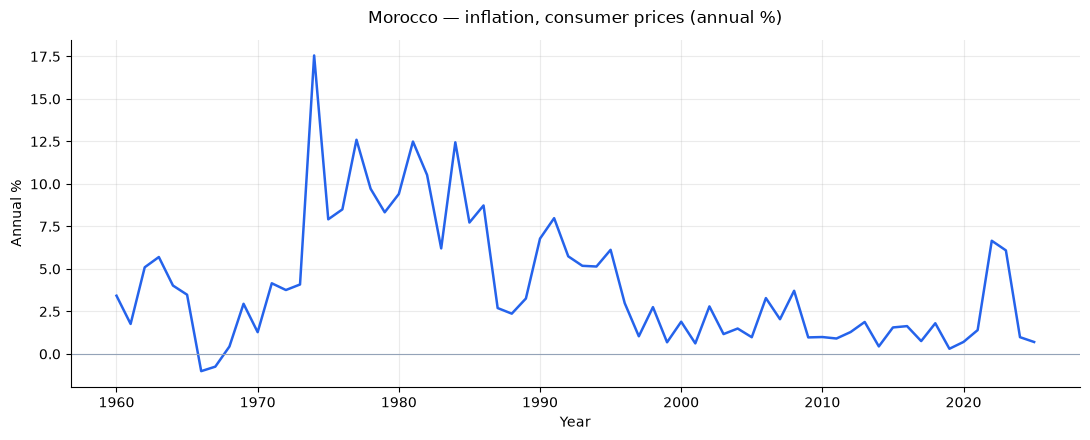

In [14]:
plot_df = clean.dropna(subset=["value"])

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(plot_df["year"], plot_df["value"], linewidth=1.8, color="#2563eb")
ax.axhline(0, color="#94a3b8", linewidth=0.8)

ax.set_title("Morocco — inflation, consumer prices (annual %)", fontsize=12, pad=12)
ax.set_xlabel("Year")
ax.set_ylabel("Annual %")
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


In [15]:
clean["value"].describe()


count    66.000000
mean      4.096722
std       3.777379
min      -1.013579
25%       1.195596
50%       2.968350
75%       6.115472
max      17.556823
Name: value, dtype: float64

In [16]:
print("highest inflation years")
print(clean.nlargest(5, "value")[["year", "value"]].to_string(index=False))
print()
print("lowest inflation years")
print(clean.nsmallest(5, "value")[["year", "value"]].to_string(index=False))


highest inflation years
 year     value
 1974 17.556823
 1977 12.597001
 1981 12.492528
 1984 12.447569
 1982 10.527807

lowest inflation years
 year     value
 1966 -1.013579
 1967 -0.748277
 2019  0.303386
 1968  0.436479
 2014  0.442310


Check the extremes against what you know of the period. Values that look
absurd (inflation of 500%, or a negative value in a year you know was
inflationary) would point at a unit or parsing problem rather than real data.

_Your note on whether the extremes look believable:_


---
## 7. Summary


In [17]:
print("SOURCE PROFILE — World Bank", INDICATOR, "/", COUNTRY)
print("-" * 52)
print(f"records            : {len(clean)}")
print(f"year range         : {clean['year'].min()}-{clean['year'].max()}")
print(f"missing values     : {clean['value'].isna().sum()}")
print(f"default page size  : {meta['per_page']}  (must be overridden)")
print(f"last updated       : {meta_all.get('lastupdated')}")
print(f"natural key        : (country_code, indicator_code, year)")


SOURCE PROFILE — World Bank FP.CPI.TOTL.ZG / MAR
----------------------------------------------------
records            : 66
year range         : 1960-2025
missing values     : 0
default page size  : 50  (must be overridden)
last updated       : 2026-10-08
natural key        : (country_code, indicator_code, year)


### Decisions this exploration settles

1. **Always pass `per_page`.** The default of 50 truncates the series without
   any error. The extractor must also assert that the received count equals
   `meta["total"]`, so a future change cannot reintroduce the problem quietly.
2. **Unpack the nested `indicator` and `country` objects** in staging.
3. **Cast `date` to an integer year.**
4. **Allow nulls in `value`.** They are real gaps, not corruption.
5. **Natural key is `(country_code, indicator_code, year)`** — this is what
   makes the load idempotent.

### Next

Write `extract/extract_worldbank.py` implementing points 1-5.
